In [18]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
DATA_PATH = (
    r"D:\Sachin Chakrawarti\Learn\done\thesis"
    r"\ctc_ectd\dataset\synthetic_cti_reports.csv"
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Please verify the CSV file path."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (10000, 17)


,id,title,text,category,date,source,url,severity,threat_actor,malware,attack_vector,target_sector,country,cve_id,mitre_technique,mitre_technique_name,indicators
0,3568,DDoS activity targeting Retail organizations,A recent threat campaign involved ddos activit...,DDoS,2021-01-01,CTI-Source-6,https://cti-reports.example.org/report/3568,High,BlackOrchid,SilverWorm,Drive-by Download,Retail,Japan,CVE-2022-39414,T1059,Command and Scripting Interpreter,IP=111.96.63.206; DOMAIN=wall-west.net; SHA256...
1,5617,Web Attack activity targeting Financial Servic...,A medium web attack campaign targeted organiza...,Web Attack,2021-01-01,CTI-Source-9,https://cti-reports.example.org/report/5617,Medium,DarkHydra,DarkLoader,Brute Force,Financial Services,United States,CVE-2024-29220,T1053,Scheduled Task/Job,IP=150.80.211.45; DOMAIN=austin-moreno.net; SH...
2,2016,Credential Theft activity targeting Retail org...,A high credential theft campaign targeted orga...,Credential Theft,2021-01-01,CTI-Source-11,https://cti-reports.example.org/report/2016,High,StormByte,SilverWorm,Exposed Service,Retail,Australia,CVE-2026-54394,T1566.001,Spearphishing Attachment,IP=143.178.240.66; DOMAIN=briggs.org; SHA256=f...
3,4000,Credential Theft activity targeting Government...,A recent threat campaign involved credential t...,Credential Theft,2021-01-01,CTI-Source-2,https://cti-reports.example.org/report/4000,Critical,NightWolf,RedLineX,Exposed Service,Government,United States,CVE-2026-60798,T1059,Command and Scripting Interpreter,IP=46.62.120.64; DOMAIN=williams.com; SHA256=3...
4,1066,Phishing activity targeting Banking organizations,A high phishing campaign targeted organization...,Phishing,2021-01-01,CTI-Source-1,https://cti-reports.example.org/report/1066,High,APT-Alpha,ShadowRAT,Brute Force,Banking,India,CVE-2023-68334,T1083,File and Directory Discovery,IP=33.169.134.207; DOMAIN=holmes-matthews.org;...



Column names:
['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators']


Identify dataset columns

In [20]:
def find_column(columns, candidates):
    lookup = {str(col).strip().lower(): col for col in columns}

    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]

    return None


TEXT_COL = find_column(
    df.columns,
    ["text", "report_text", "description", "content",
     "narrative", "report", "body"]
)

TITLE_COL = find_column(
    df.columns,
    ["title", "report_title", "name"]
)

LABEL_COL = find_column(
    df.columns,
    ["attack_type", "label", "category", "threat_type",
     "class", "target"]
)

DATE_COL = find_column(
    df.columns,
    ["date", "published_date", "report_date",
     "created_at", "timestamp"]
)

print("Text column:", TEXT_COL)
print("Title column:", TITLE_COL)
print("Label column:", LABEL_COL)
print("Date column:", DATE_COL)

if TEXT_COL is None:
    print("\nAvailable columns:", df.columns.tolist())
    raise ValueError(
        "Text column not detected. Set TEXT_COL manually "
        "using one of the available column names."
    )

if LABEL_COL is None:
    raise ValueError(
        "Target label column not detected. "
        "Set LABEL_COL manually."
    )

Text column: text
Title column: title
Label column: category
Date column: date


Clean and prepare the dataset

In [21]:
df = df.copy()

df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str).str.strip()
df[LABEL_COL] = df[LABEL_COL].fillna("").astype(str).str.strip()

df = df[
    (df[TEXT_COL] != "") &
    (df[LABEL_COL] != "")
].copy()

df = df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

if TITLE_COL is not None:
    df[TITLE_COL] = df[TITLE_COL].fillna("").astype(str).str.strip()
    df["model_text"] = (
        df[TITLE_COL] + " " + df[TEXT_COL]
    ).str.strip()
else:
    df["model_text"] = df[TEXT_COL]

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
display(df[LABEL_COL].value_counts().to_frame("report_count"))

display(df[["model_text", LABEL_COL]].head())

Cleaned dataset shape: (10000, 18)

Class distribution:


,report_count
category,
Ransomware,1041
Web Attack,1040
DDoS,1027
Vulnerability,1020
Credential Theft,993
Data Breach,990
Botnet,987
Malware,986
Phishing,983


,model_text,category
0,DDoS activity targeting Retail organizations A...,DDoS
1,Web Attack activity targeting Financial Servic...,Web Attack
2,Credential Theft activity targeting Retail org...,Credential Theft
3,Credential Theft activity targeting Government...,Credential Theft
4,Phishing activity targeting Banking organizati...,Phishing


Exploratory Data Analysis (EDA)

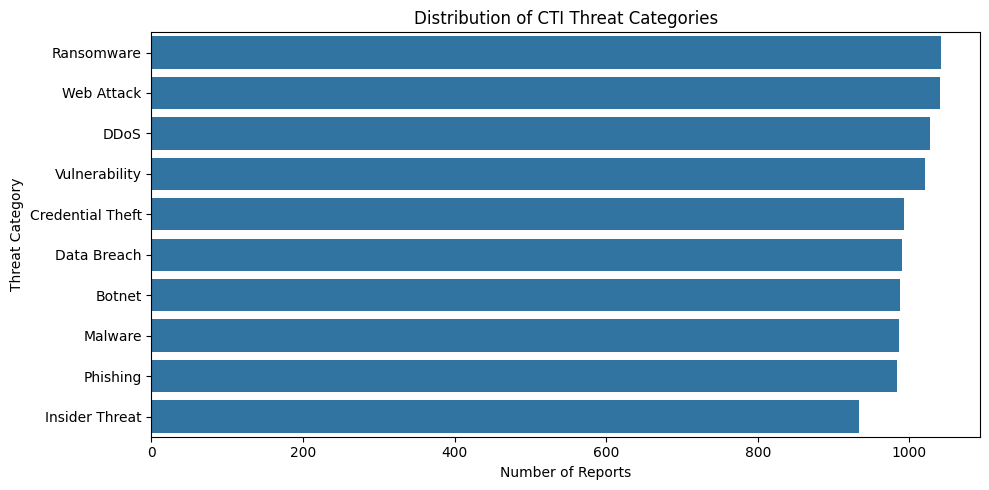

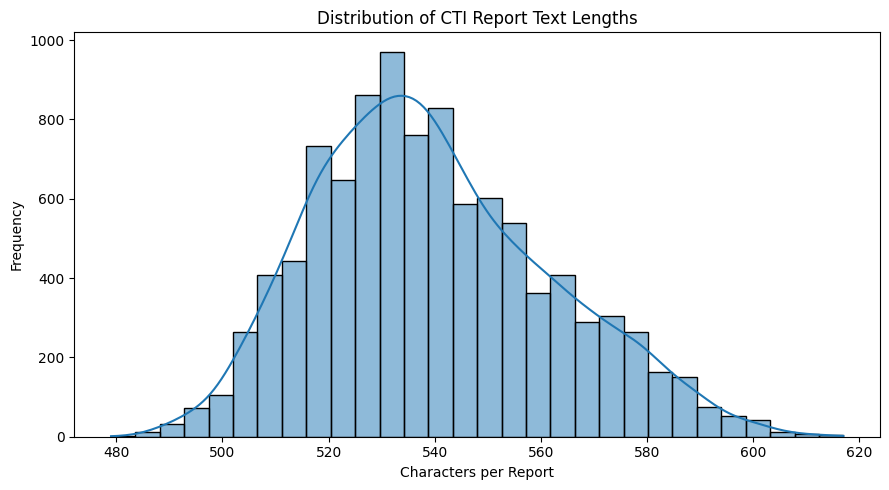

Missing values:


,missing_values
id,0
title,0
text,0
category,0
date,0
source,0
url,0
severity,0
threat_actor,0
malware,0


Number of classes: 10
Total reports: 10000


In [22]:
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    y=LABEL_COL,
    order=df[LABEL_COL].value_counts().index
)
plt.title("Distribution of CTI Threat Categories")
plt.xlabel("Number of Reports")
plt.ylabel("Threat Category")
plt.tight_layout()
plt.show()

df["text_length"] = df["model_text"].str.len()

plt.figure(figsize=(9, 5))
sns.histplot(df["text_length"], bins=30, kde=True)
plt.title("Distribution of CTI Report Text Lengths")
plt.xlabel("Characters per Report")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Missing values:")
display(df.isnull().sum().to_frame("missing_values"))

print("Number of classes:", df[LABEL_COL].nunique())
print("Total reports:", len(df))

Prepare training and testing data

In [23]:
X = df["model_text"]
y = df[LABEL_COL]

class_counts = y.value_counts()
can_stratify = (
    y.nunique() > 1 and
    class_counts.min() >= 2
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y if can_stratify else None
)

print("Training reports:", len(X_train))
print("Testing reports:", len(X_test))
print("Training classes:", y_train.nunique())

Training reports: 8000
Testing reports: 2000
Training classes: 10


Train three machine learning models

In [24]:
models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            stop_words="english"
        )),
        ("classifier", MultinomialNB())
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            stop_words="english",
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1": f1
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    "Weighted F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Logistic Regression...
Training Multinomial Naive Bayes...
Training Linear SVM...


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0


Classification report and confusion matrix

Best baseline model: Logistic Regression

Classification Report:

                  precision    recall  f1-score   support

          Botnet       1.00      1.00      1.00       197
Credential Theft       1.00      1.00      1.00       199
            DDoS       1.00      1.00      1.00       205
     Data Breach       1.00      1.00      1.00       198
  Insider Threat       1.00      1.00      1.00       187
         Malware       1.00      1.00      1.00       197
        Phishing       1.00      1.00      1.00       197
      Ransomware       1.00      1.00      1.00       208
   Vulnerability       1.00      1.00      1.00       204
      Web Attack       1.00      1.00      1.00       208

        accuracy                           1.00      2000
       macro avg       1.00      1.00      1.00      2000
    weighted avg       1.00      1.00      1.00      2000



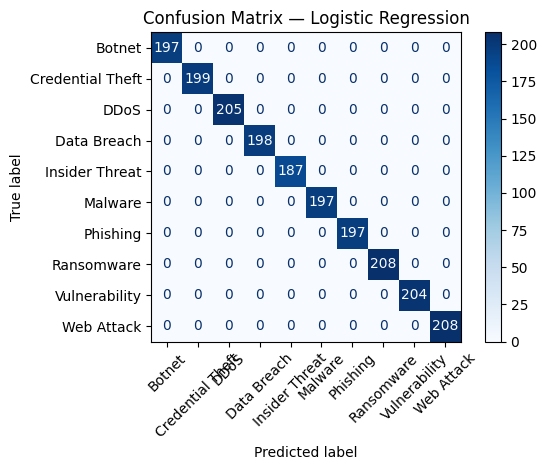

In [25]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best baseline model:", best_model_name)
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

Temporal data preparation

In [26]:
if DATE_COL is not None:
    df["parsed_date"] = pd.to_datetime(
        df[DATE_COL],
        errors="coerce",
        utc=True
    )

    temporal_df = df.dropna(subset=["parsed_date"]).copy()
    temporal_df["month"] = (
        temporal_df["parsed_date"]
        .dt.tz_convert(None)
        .dt.to_period("M")
        .astype(str)
    )

    print("Reports with valid dates:", len(temporal_df))
    print("Months covered:", temporal_df["month"].nunique())

    display(
        temporal_df.groupby("month")
        .size()
        .reset_index(name="report_count")
    )
else:
    temporal_df = pd.DataFrame()
    print(
        "No date column detected. Temporal analysis cannot run "
        "until valid report dates are available."
    )

Reports with valid dates: 10000
Months covered: 69


,month,report_count
0,2021-01,139
1,2021-02,135
2,2021-03,155
3,2021-04,135
4,2021-05,133
...,...,...
64,2026-05,165
65,2026-06,151
66,2026-07,143
67,2026-08,176


Temporal topic modeling with NMF

Topic 1: activity, followed malicious, gain, followed, incident affecting, activity mapped, actor, activity involving, affecting, incident
Topic 2: activity, campaign, access linked, initial access, sector initial, additional activity, linked, affected systems, affected, campaign involved
Topic 3: behavior involving, activity corresponds, corresponds mitre, corresponds, threat intelligence, detected, monitoring, intelligence, intelligence monitoring, investigation activity
Topic 4: activity, located, investigation reported, targeted organizations, technique, reported mitre, reported, security analysts, activity identified, campaign targeted
Topic 5: web, attack, web attack, attack activity, identified web, attack behavior, detected web, involved web, attack incident, attack campaign


dominant_topic,1,2,3,4,5
month,,,,,
2021-01,0.237,0.216,0.230,0.223,0.094
2021-02,0.230,0.267,0.193,0.193,0.119
2021-03,0.181,0.239,0.219,0.271,0.090
2021-04,0.185,0.178,0.244,0.289,0.104
2021-05,0.218,0.211,0.256,0.241,0.075
...,...,...,...,...,...
2026-05,0.218,0.255,0.242,0.218,0.067
2026-06,0.205,0.225,0.205,0.272,0.093
2026-07,0.245,0.238,0.133,0.210,0.175


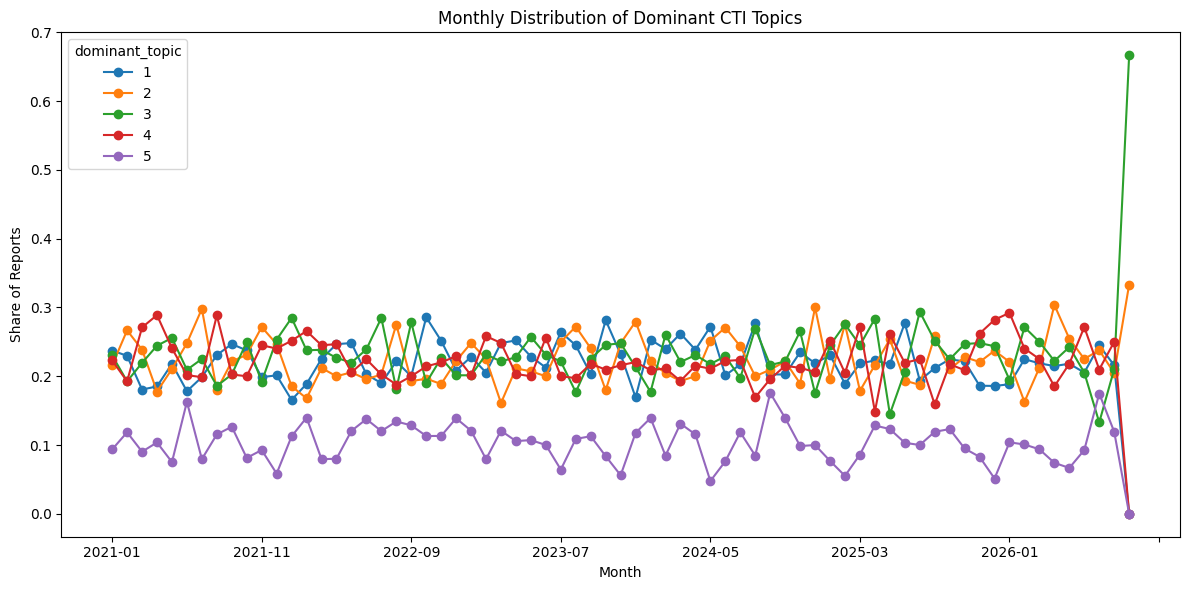

In [27]:
from sklearn.decomposition import NMF

if not temporal_df.empty and len(temporal_df) >= 5:
    topic_vectorizer = TfidfVectorizer(
        max_features=5000,
        stop_words="english",
        ngram_range=(1, 2)
    )

    topic_matrix = topic_vectorizer.fit_transform(
        temporal_df["model_text"]
    )

    n_topics = min(5, topic_matrix.shape[0], topic_matrix.shape[1])

    if n_topics >= 2:
        nmf_model = NMF(
            n_components=n_topics,
            random_state=RANDOM_STATE,
            init="nndsvda",
            max_iter=500
        )

        topic_weights = nmf_model.fit_transform(topic_matrix)
        feature_names = topic_vectorizer.get_feature_names_out()

        for topic_id, components in enumerate(nmf_model.components_):
            top_indices = components.argsort()[-10:][::-1]
            top_words = [feature_names[i] for i in top_indices]

            print(f"Topic {topic_id + 1}: {', '.join(top_words)}")

        topic_columns = [
            f"Topic_{i + 1}" for i in range(n_topics)
        ]

        for i, column in enumerate(topic_columns):
            temporal_df[column] = topic_weights[:, i]

        temporal_df["dominant_topic"] = (
            topic_weights.argmax(axis=1) + 1
        )

        monthly_topic_counts = pd.crosstab(
            temporal_df["month"],
            temporal_df["dominant_topic"]
        )

        monthly_topic_shares = monthly_topic_counts.div(
            monthly_topic_counts.sum(axis=1),
            axis=0
        ).fillna(0)

        display(monthly_topic_shares.round(3))

        monthly_topic_shares.plot(
            figsize=(12, 6),
            marker="o"
        )
        plt.title("Monthly Distribution of Dominant CTI Topics")
        plt.xlabel("Month")
        plt.ylabel("Share of Reports")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough terms or reports to fit multiple topics.")
else:
    print("Insufficient dated reports for temporal topic modeling.")

Exploratory emerging-pattern alerts

In [28]:
alerts = []

if "monthly_topic_shares" in globals():
    months = list(monthly_topic_shares.index)

    for i in range(1, len(months)):
        previous_month = months[i - 1]
        current_month = months[i]

        for topic_id in monthly_topic_shares.columns:
            previous_share = monthly_topic_shares.loc[
                previous_month, topic_id
            ]
            current_share = monthly_topic_shares.loc[
                current_month, topic_id
            ]

            increase = current_share - previous_share

            current_count = monthly_topic_counts.loc[
                current_month, topic_id
            ]

            if increase >= 0.10 and current_count >= 2:
                alerts.append({
                    "Previous Month": previous_month,
                    "Current Month": current_month,
                    "Topic": topic_id,
                    "Previous Share": previous_share,
                    "Current Share": current_share,
                    "Increase": increase,
                    "Current Report Count": current_count
                })

alerts_df = pd.DataFrame(alerts)

if not alerts_df.empty:
    display(alerts_df.round(3))
else:
    print(
        "No topic passed the exploratory alert threshold. "
        "This does not establish that no emerging threats exist."
    )

,Previous Month,Current Month,Topic,Previous Share,Current Share,Increase,Current Report Count
0,2024-11,2024-12,2,0.189,0.300,0.111,48
1,2025-04,2025-05,4,0.149,0.261,0.112,36
2,2026-08,2026-09,3,0.210,0.667,0.456,2


Test a new CTI report

In [29]:
new_report = """
Multiple organizations report suspicious credential theft activity.
Attackers use phishing emails to obtain account credentials
and attempt unauthorized access to corporate systems.
"""

predicted_category = best_model.predict([new_report])[0]

print("New CTI Report:")
print(new_report)
print("\nPredicted Threat Category:", predicted_category)

New CTI Report:

Multiple organizations report suspicious credential theft activity.
Attackers use phishing emails to obtain account credentials
and attempt unauthorized access to corporate systems.


Predicted Threat Category: Credential Theft


Save the best classifier

In [30]:
PROJECT_ROOT = (
    r"D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd"
)

ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts")
os.makedirs(ARTIFACT_DIR, exist_ok=True)

model_path = os.path.join(
    ARTIFACT_DIR,
    "cti_text_classifier.joblib"
)

joblib.dump(best_model, model_path)

print("Selected model:", best_model_name)
print("Saved model to:", model_path)

Selected model: Logistic Regression
Saved model to: D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd\artifacts\cti_text_classifier.joblib


Final research summary

In [31]:
print("=" * 60)
print("CTI THREAT ANALYSIS — EXPERIMENT SUMMARY")
print("=" * 60)

print("Dataset reports:", len(df))
print("Threat categories:", df[LABEL_COL].nunique())
print("Training reports:", len(X_train))
print("Testing reports:", len(X_test))
print("Best baseline:", best_model_name)

display(results_df.round(4))

print("\nResearch limitations:")
print("1. Synthetic data may not represent real CTI distributions.")
print("2. Classification metrics depend on dataset quality and splits.")
print("3. NMF topics are exploratory and require human interpretation.")
print("4. Topic-frequency increases are alerts, not confirmed threats.")
print("5. Real-time performance requires separate latency testing.")

CTI THREAT ANALYSIS — EXPERIMENT SUMMARY
Dataset reports: 10000
Threat categories: 10
Training reports: 8000
Testing reports: 2000
Best baseline: Logistic Regression


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0



Research limitations:
1. Synthetic data may not represent real CTI distributions.
2. Classification metrics depend on dataset quality and splits.
3. NMF topics are exploratory and require human interpretation.
4. Topic-frequency increases are alerts, not confirmed threats.
5. Real-time performance requires separate latency testing.
